# Dynamics 03 — Sympathie contre engagement : la statique comparative qui les sépare (version C# / .NET)

**Navigation** : [<< Dynamics-01-Jeux-Repetes-Folk-Theorem-CSharp](Dynamics-01-Jeux-Repetes-Folk-Theorem-CSharp.ipynb) | [Index](README.md) | [Dynamics-03-Sympathie-vs-Engagement-Python (jumeau Python) >>](Dynamics-03-Sympathie-vs-Engagement-Python.ipynb)

Ce notebook est la **réalisation native C# / .NET** du protocole de mesure qui répond à une limite honnête de GT-06c §7d. La version Python est le jumeau de référence ; ici, le même banc tourne sur le moteur **.NET Interactive** avec **MathNet.Numerics** réel (distribution de Student, résolution matricielle pour l'IRLS). Le même comportement observé recevait deux verdicts opposés selon la valeur du paramètre de sympathie `alpha` posé par l'analyste : le verdict dépendait du choix de l'analyste, pas des données.

La distinction de Sen (1977) — **sympathie** (le bien-être d'autrui entre dans mon utilité) contre **engagement** (agir contre son propre classement de bien-être, en suivant une règle) — est conceptuelle. La séparer **empiriquement** demande une observation que la trajectoire de coopération seule ne porte pas. Ce notebook construit cette observation :

> **faire varier les gains d'AUTRUI seuls, à gains propres strictement fixes, et mesurer la pente du taux de coopération.**

Une coopération qui **répond** aux gains d'autrui est compatible avec la sympathie et incompatible avec l'engagement pur. Une coopération **plate** est compatible avec l'engagement et incompatible avec la sympathie. La pente transforme `alpha` d'un paramètre libre en une **quantité mesurée**.

## Objectifs d'apprentissage

À l'issue de ce notebook, vous saurez :

1. **Montrer** qu'un classifieur à paramètre posé rend des verdicts contradictoires sur une même trajectoire (le problème d'identification).
2. **Construire** une grille de jeux où seuls les gains d'autrui varient, à gains propres byte-identiques — et le vérifier en code.
3. **Distinguer** les prédictions des deux mécanismes : réponse aux gains d'autrui (sympathie) contre insensibilité (engagement).
4. **Estimer** la pente du taux de coopération avec son incertitude (multi-graines, t de Student via MathNet), et `alpha` **depuis la pente** par maximum de vraisemblance.
5. **Valider** un estimateur par contrôles négatifs avant de l'appliquer — et accepter un verdict « non identifié » quand le bruit l'impose.

### Prérequis

- [GameTheory-06c](Dynamics-01-Jeux-Repetes-Folk-Theorem-CSharp.ipynb) §7 (le régime sans punition, l'adversaire sans mémoire, le retrait de la menace).
- Bases de C# / .NET ; notion d'estimation par maximum de vraisemblance (une intuition suffit, le code est explicite).
- Aucune API externe : tout tourne en .NET, déterministe par graine, avec MathNet.Numerics pour la distribution de Student et l'algèbre linéaire de l'IRLS.

### Durée estimée : 45 minutes

## 1. Le problème : un verdict qui dépend de l'analyste, pas des données

Le banc de GT-06c §7d fonctionne ainsi : dans un Dilemme du Prisonnier répété **sans punition** (l'adversaire est sans mémoire, aucune séquence de nos coups ne peut être punie), un joueur coopère. Le classifieur calcule l'écart d'intérêt sur l'utilité transformée `U = u_mien + alpha * u_autrui` :

- `u_coop = R + alpha * R` (je coopère : je touche R, autrui touche R),
- `u_dev = T + alpha * S` (je dévie : je touche T, autrui touche S),

et rend un verdict **selon la valeur d'alpha choisie**. Démonstration sur la même trajectoire observée (le joueur coopère sur tout l'horizon) :

In [1]:
// ============================================================
// Infrastructure du banc — constantes + fonctions de mesure.
// MathNet.Numerics réel : distribution de Student + algèbre
// linéaire (résolution 2x2 de l'IRLS).
// ============================================================
#r "nuget: MathNet.Numerics, 5.0.0"
using MathNet.Numerics.LinearAlgebra;
using MathNet.Numerics.Distributions;

// --- barème canonique du banc GT-06c (jeu étape, joueur observé = lignes) ---
double T = 5.0, R = 3.0, P = 1.0, S = 0.0;   // tentation, récompense, punition, soumis
double delta = 0.6;                            // patience (delta* grim = 0.5)
double S_AUTRE = 0.0;                          // gain d'autrui quand je dévie — fixe
int[] SEEDS = { 0, 1, 7, 42, 99 };            // multi-graines
int HORIZON = 200;                             // périodes par trajectoire
double BETA = 2.0;                             // bruit de choix (logit)

// --- grille : R_autre balaie 0 -> 10 (21 cellules, pas 0.5) ---
int NCELL = 21;
double[] GRILLE = new double[NCELL];
for (int gi = 0; gi < NCELL; gi++) GRILLE[gi] = Math.Round(gi * 0.5, 2);

// --- sigmoid borné (contrôle du logit) ---
static double Sigmoid(double v) => 1.0 / (1.0 + Math.Exp(-Math.Clamp(v, -30.0, 30.0)));

// --- probabilité de coopérer, modèle sympathie-logit ---
static double PCoopSympathie(double rAutre, double alpha, double beta,
                             double R, double T, double sAutre)
    => Sigmoid(beta * ((R + alpha * rAutre) - (T + alpha * sAutre)));

// --- écart d'intérêt (dévier - coopérer), régime sans punition ---
static double EcartInteret(double alpha, double R, double S, double T, double delta,
                           double rAutre = -1, double sAutre = -1)
{
    double rA = rAutre < 0 ? R : rAutre;
    double sA = sAutre < 0 ? S : sAutre;
    double uCoop = R + alpha * rA;
    double uDev  = T + alpha * sA;
    return (uDev - uCoop) / (1.0 - delta);
}

// --- taux de coopération (graines x cellules) d'un agent ---
// une graine = UN tirage Random réutilisé sur les cellules (fidèle au jumeau Python).
static double[,] TauxCooperation(Func<double,double> agent, double[] grille, int[] seeds, int horizon)
{
    double[,] taux = new double[seeds.Length, grille.Length];
    for (int i = 0; i < seeds.Length; i++)
    {
        var rng = new Random(seeds[i]);
        for (int j = 0; j < grille.Length; j++)
        {
            double p = agent(grille[j]);
            int coop = 0;
            for (int t = 0; t < horizon; t++)
                if (rng.NextDouble() < p) coop++;
            taux[i, j] = (double)coop / horizon;
        }
    }
    return taux;
}

// --- pente de régression simple (moindres carrés) ---
static double Pente(double[] x, double[] y)
{
    double mx = x.Average(), my = y.Average();
    double sxx = 0, sxy = 0;
    for (int i = 0; i < x.Length; i++) { sxx += (x[i]-mx)*(x[i]-mx); sxy += (x[i]-mx)*(y[i]-my); }
    return sxy / sxx;
}

// --- pente moyenne ± IC95 (une régression par graine, Student via MathNet) ---
static (double pente, double lo, double hi) PenteAvecIC(double[,] taux, double[] grille)
{
    int ns = taux.GetLength(0);
    double[] pentes = new double[ns];
    for (int i = 0; i < ns; i++)
    {
        double[] y = new double[grille.Length];
        for (int j = 0; j < grille.Length; j++) y[j] = taux[i, j];
        pentes[i] = Pente(grille, y);
    }
    double mean = pentes.Average();
    double vv = 0; for (int i = 0; i < ns; i++) vv += (pentes[i]-mean)*(pentes[i]-mean);
    double se = Math.Sqrt(vv / (ns - 1)) / Math.Sqrt(ns);
    double tCrit = StudentT.InvCDF(0, 1, ns - 1, 0.975);   // MathNet réel pour Student
    return (mean, mean - tCrit * se, mean + tCrit * se);
}

// --- log-vraisemblance binomiale du modèle sympathie-logit sur toute la grille ---
static double LogLikBinom(double alpha, double beta, double[,] taux, double[] grille, int horizon,
                          double R, double T, double sAutre)
{
    double ll = 0;
    for (int i = 0; i < taux.GetLength(0); i++)
        for (int j = 0; j < grille.Length; j++)
        {
            int k = (int)Math.Round(taux[i, j] * horizon);
            double p = Math.Clamp(PCoopSympathie(grille[j], alpha, beta, R, T, sAutre), 1e-12, 1 - 1e-12);
            ll += k * Math.Log(p) + (horizon - k) * Math.Log(1 - p);
        }
    return ll;
}

// --- MLE (alpha, beta) par balayage de grille + IC par profil de vraisemblance ---
static (double alpha, double beta, double aLo, double aHi) EstimeAlpha(
    double[,] taux, double[] grille, int horizon, double R, double T, double sAutre)
{
    int na = 301, nb = 60;
    double[] alphas = new double[na];
    for (int i = 0; i < na; i++) alphas[i] = Math.Round(i * 0.01, 3);
    double[] betas = new double[nb];
    for (int j = 0; j < nb; j++) betas[j] = Math.Round(0.05 * Math.Pow(50.0 / 0.05, j / (nb - 1.0)), 4);
    double llMax = double.NegativeInfinity; int iStar = 0, jStar = 0;
    double[] profil = new double[na];
    for (int i = 0; i < na; i++)
    {
        double bestForAlpha = double.NegativeInfinity;
        for (int j = 0; j < nb; j++)
        {
            double ll = LogLikBinom(alphas[i], betas[j], taux, grille, horizon, R, T, sAutre);
            if (ll > bestForAlpha) bestForAlpha = ll;
            if (ll > llMax) { llMax = ll; iStar = i; jStar = j; }
        }
        profil[i] = bestForAlpha;
    }
    var dansIC = Enumerable.Range(0, na)
        .Where(i => profil[i] >= llMax - 1.92).Select(i => alphas[i]).ToList();
    return (alphas[iStar], betas[jStar], dansIC.Min(), dansIC.Max());
}

// --- ajustement logit par IRLS (résolution 2x2 via MathNet) ---
// Régularisé (fix de la « séparation parfaite ») : une pénalité ridge `ridge`
// sur (b0, b1) borne le système 2x2, et un cap `cap` sur l'amplitude de chaque
// coefficient est le filet de sécurité. Sans eux, le contrôle sympathie est
// séparé : la vraisemblance croît quand les coefficients s'envolent et le IRLS
// non pénalisé diverge (mesuré : penteLogit -> -2,3e7, alpha -> -1,1e7). La
// MLE en grille est bornée (alpha dans [0,3]) ; le IRLS l'est désormais aussi,
// si bien que les deux estimateurs deviennent comparables sur ce cas calibré.
static (double penteLogit, double intercept) AjustementLogitIRLS(double[] x, double[] taux, double repetitions,
                                                                  double ridge = 100.0, double cap = 3.0)
{
    int n = x.Length;
    double b0 = 0, b1 = 0;
    for (int iter = 0; iter < 100; iter++)
    {
        double[] p = new double[n], variance = new double[n], poids = new double[n], z = new double[n];
        for (int i = 0; i < n; i++)
        {
            double eta = b1 * x[i] + b0;
            p[i] = Sigmoid(eta);
            variance[i] = Math.Max(p[i] * (1 - p[i]), 1e-9);
            poids[i] = repetitions * variance[i];
            z[i] = eta + (taux[i] - p[i]) / variance[i];
        }
        double a00 = 0, a01 = 0, a11 = 0, bb0 = 0, bb1 = 0;
        for (int i = 0; i < n; i++)
        { a00 += poids[i]*x[i]*x[i]; a01 += poids[i]*x[i]; a11 += poids[i];
          bb0 += poids[i]*x[i]*z[i]; bb1 += poids[i]*z[i]; }
        a00 += ridge; a11 += ridge;                    // pénalité ridge sur le système 2x2
        var M = Matrix<double>.Build.DenseOfArray(new double[2,2]{ {a00, a01}, {a01, a11} });
        var B = Vector<double>.Build.DenseOfArray(new double[]{ bb0, bb1 });
        var sol = M.Solve(B);
        double nb0 = Math.Clamp(sol[0], -cap, cap);     // cap de sécurité sur l'amplitude
        double nb1 = Math.Clamp(sol[1], -cap, cap);
        double change = Math.Abs(nb0 - b0) + Math.Abs(nb1 - b1);
        b0 = nb0; b1 = nb1;
        if (change < 1e-10) break;
    }
    return (b1, b0);
}

// --- alpha par IRLS, avec IC95 bootstrap sur les graines ---
static (double alpha, double lo, double hi, double intercept) AlphaIRLSBootstrap(
    double[,] tauxParGraine, double betaDeclare, int horizon, double[] grille, int repetitions = 1000)
{
    var rng = new Random(2024);
    int ns = tauxParGraine.GetLength(0);
    double[] alphas = new double[repetitions];
    for (int b = 0; b < repetitions; b++)
    {
        double[] tauxBoot = new double[grille.Length];
        for (int j = 0; j < grille.Length; j++)
        {
            double s = 0;
            for (int k = 0; k < ns; k++) s += tauxParGraine[rng.Next(ns), j];
            tauxBoot[j] = s / ns;
        }
        var (plB, _) = AjustementLogitIRLS(grille, tauxBoot, horizon * ns);
        alphas[b] = plB / betaDeclare;
    }
    double[] tauxMoyen = new double[grille.Length];
    for (int j = 0; j < grille.Length; j++){
        double s = 0; for (int i = 0; i < ns; i++) s += tauxParGraine[i, j]; tauxMoyen[j] = s / ns;
    }
    var (pl, ic) = AjustementLogitIRLS(grille, tauxMoyen, horizon * ns);
    Array.Sort(alphas);
    int loIdx = (int)Math.Round(0.025 * (repetitions - 1));
    int hiIdx = (int)Math.Round(0.975 * (repetitions - 1));
    return (pl / betaDeclare, alphas[loIdx], alphas[hiIdx], ic);
}

// --- engagement bruité : règle suivie avec conformité donnée, graine indépendante par cellule ---
static double[,] TauxEngagementBruit(double[] grille, int[] seeds, int horizon, double conformite)
{
    double[,] taux = new double[seeds.Length, grille.Length];
    for (int i = 0; i < seeds.Length; i++)
      for (int j = 0; j < grille.Length; j++)
      {
        var rng = new Random(seeds[i] * 1000003 + (int)Math.Round(grille[j] * 1000));
        int coop = 0;
        for (int t = 0; t < horizon; t++)
        {
            bool conforme = rng.NextDouble() < conformite;
            int actionHorsRegle = rng.Next(2);
            coop += (conforme ? 1 : actionHorsRegle);
        }
        taux[i, j] = (double)coop / horizon;
      }
    return taux;
}

// --- construit la figure SVG (3 signatures) à partir des taux moyens ---
static string ConstruireSvg(double[] x, double[] yS, double[] yE, double[] yA)
{
    int W = 760, H = 440, mL = 70, mB = 50, mT = 30, mR = 20;
    double xMax = 10.0, yMax = 1.0;
    double sx = (W - mL - mR) / xMax, sy = (H - mT - mB) / yMax;
    string Px(double vx) => ((mL + vx * sx).ToString("F1"));
    string Py(double vy) => ((H - mB - vy * sy).ToString("F1"));
    Func<double[], string> pts = ys =>
        string.Join(" ", Enumerable.Range(0, x.Length).Select(i => $"{Px(x[i])},{Py(ys[i])}"));
    var sb = new System.Text.StringBuilder();
    sb.Append($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}' " +
              "font-family='sans-serif' font-size='13'>");
    sb.Append($"<rect width='{W}' height='{H}' fill='white'/>");
    // axes
    sb.Append($"<line x1='{mL}' y1='{H-mB}' x2='{W-mR}' y2='{H-mB}' stroke='black'/>");
    sb.Append($"<line x1='{mL}' y1='{mT}' x2='{mL}' y2='{H-mB}' stroke='black'/>");
    sb.Append($"<text x='{(W-mR)/2}' y='{H-12}' text-anchor='middle'>R_autre : gain d'AUTRUI quand je coopère (mes gains inchangés)</text>");
    sb.Append($"<text x='16' y='{(H-mB)/2}' text-anchor='middle' transform='rotate(-90 16 {(H-mB)/2})'>taux de coopération</text>");
    sb.Append($"<text x='{(W-mR)/2}' y='{mT-8}' text-anchor='middle' font-weight='bold'>Statique comparative : trois mécanismes, trois signatures</text>");
    sb.Append($"<polyline points='{pts(yS)}' fill='none' stroke='#1f77b4' stroke-width='2.5'/>");
    sb.Append($"<polyline points='{pts(yE)}' fill='none' stroke='#d62728' stroke-width='2.5'/>");
    sb.Append($"<polyline points='{pts(yA)}' fill='none' stroke='#7f7f7f' stroke-width='2.5'/>");
    double lx = mL + 0.15 * (W - mL - mR), ly = mT + 10;
    sb.Append($"<line x1='{lx}' y1='{ly+4}' x2='{lx+26}' y2='{ly+4}' stroke='#1f77b4' stroke-width='2.5'/>");
    sb.Append($"<text x='{lx+32}' y='{ly+9}'>sympathie (alpha=0.5) — croissante</text>");
    sb.Append($"<line x1='{lx}' y1='{ly+24}' x2='{lx+26}' y2='{ly+24}' stroke='#d62728' stroke-width='2.5'/>");
    sb.Append($"<text x='{lx+32}' y='{ly+29}'>engagement (règle) — plate haute</text>");
    sb.Append($"<line x1='{lx}' y1='{ly+44}' x2='{lx+26}' y2='{ly+44}' stroke='#7f7f7f' stroke-width='2.5'/>");
    sb.Append($"<text x='{lx+32}' y='{ly+49}'>auto-intérêt (alpha=0) — plate basse</text>");
    sb.Append("</svg>");
    return sb.ToString();
}

Console.WriteLine("Infrastructure du banc prête : " + SEEDS.Length + " graines, horizon " + HORIZON +
                  " périodes, grille " + NCELL + " cellules (R_autre 0..10).");
Console.WriteLine("Moteur .NET : MathNet.Numerics (Student + algèbre linéaire IRLS). t(0.975, df=4) = " +
                  StudentT.InvCDF(0, 1, 4, 0.975).ToString("F4") + " (réf. 2.776).");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages MathNet.Numerics, 5.0.0

Infrastructure du banc prête : 5 graines, horizon 200 périodes, grille 21 cellules (R_autre 0..10).


Moteur .NET : MathNet.Numerics (Student + algèbre linéaire IRLS). t(0.975, df=4) = 2,7764 (réf. 2.776).


In [2]:
// LA MÊME trajectoire observée : le joueur coopère sur tout l'horizon, sans punition possible.
string[] trajectoire = Enumerable.Repeat("Cooperer", 10).ToArray();

double alphaEtoile = (T - R) / (R - S);
double ecartPur = (T - R) / (1.0 - delta);
Console.WriteLine($"Barème : T={T}, R={R}, P={P}, S={S}  |  delta = {delta} (seuil grim delta* = 0.5)");
Console.WriteLine($"Trajectoire observée (sans punition) : {{Cooperer}}");
Console.WriteLine($"Écart pur sans sympathie = (T-R)/(1-delta) = {ecartPur:F2}");
foreach (double alphaPose in new[] { 1.0, 0.0 })
{
    double ecart = EcartInteret(alphaPose, R, S, T, delta);
    string verdict = ecart <= 0
        ? "COOPÉRATION EXPLIQUÉE PAR L'UTILITÉ TRANSFORMÉE (sympathie)"
        : "COOPÉRATION CONTRE-INTÉRÊT : résidu = engagement au sens de Sen";
    Console.WriteLine($"alpha posé = {alphaPose:F1} -> écart {ecart:+0.00} -> {verdict}");
}
Console.WriteLine($"Seuil de sympathie alpha* = (T-R)/(R-S) = {alphaEtoile:F3}");
Console.WriteLine();
Console.WriteLine("Deux verdicts opposés, une seule trajectoire : alpha* n'est pas un seuil de");
Console.WriteLine("diagnostic, c'est une frontière d'indiscernabilité. Rien dans les données de la");
Console.WriteLine("trajectoire ne révèle alpha — il faut une observation nouvelle.");

Barème : T=5, R=3, P=1, S=0  |  delta = 0,6 (seuil grim delta* = 0.5)


Trajectoire observée (sans punition) : {Cooperer}


Écart pur sans sympathie = (T-R)/(1-delta) = 5,00


alpha posé = 1,0 -> écart -+2,50 -> COOPÉRATION EXPLIQUÉE PAR L'UTILITÉ TRANSFORMÉE (sympathie)


alpha posé = 0,0 -> écart +5,00 -> COOPÉRATION CONTRE-INTÉRÊT : résidu = engagement au sens de Sen


Seuil de sympathie alpha* = (T-R)/(R-S) = 0,667


Deux verdicts opposés, une seule trajectoire : alpha* n'est pas un seuil de


diagnostic, c'est une frontière d'indiscernabilité. Rien dans les données de la


trajectoire ne révèle alpha — il faut une observation nouvelle.


Le verdict n'est pas identifié : sur des données de coopération **seules**, sympathie et engagement sont observationnellement équivalents. Ce n'est pas un défaut de GT-06c — c'est une limite réelle de ce qu'une trajectoire peut porter.

## 2. L'observation qui sépare : faire varier les gains d'AUTRUI

Les deux mécanismes ne dépendent pas des mêmes quantités :

| Mécanisme | Ce qui entre dans la décision | Prédiction sur la grille |
|---|---|---|
| **Sympathie** (`U = u_mien + alpha * u_autrui`) | le bien-être d'autrui, pondéré | coopération **croissante** en `R_autre` |
| **Engagement** (règle suivie contre son intérêt) | la règle — pas les gains d'autrui | coopération **plate** en `R_autre` |
| Auto-intérêt (`alpha = 0`, pas de règle) | rien que mes gains | coopération **plate et basse** |

D'où le protocole : un même jeu sans punition, où la **ligne de gains du joueur observé reste byte-identique** de cellule en cellule, tandis que la **colonne d'autrui** (`R_autre`) balaie une plage. La **pente** du taux de coopération en `R_autre` est la quantité qui sépare les mécanismes — et `alpha` cesse d'être un paramètre libre : il devient une quantité estimée **depuis** cette réponse.

## 3. La grille : gains propres gelés, gains d'autrui balayés

Chaque cellule de la grille est un jeu étape complet. La condition qui rend la statique interprétable est stricte : **la matrice de gains du joueur observé ne doit pas bouger d'une cellule à l'autre** — sinon une variation du taux de coopération pourrait refléter un changement de MES gains, et la pente ne mesurerait plus rien. Nous construisons la grille puis nous **vérifions en code** cette invariance (critère d'acceptance du protocole).

In [3]:
// Grille : R_autre balaie 0 -> 10 (21 cellules, pas 0.5), S_autre fixé à 0.
// La matrice propre (T, R, P, S) est gelée UNE fois, hors de la boucle.
double[] PROPRE = { T, R, P, S };           // ligne du joueur observé — ne varie JAMAIS
// jeu étape de la cellule : (moi, autrui) par issue
//   je_coopere = (R, r_autre) ; je_devie = (T, S_AUTRE)

// === VÉRIFICATION (acceptance 1) : gains propres byte-identiques sur toute la grille ===
bool byteIdentique = true;
for (int i = 1; i < NCELL; i++)
{
    // mes gains si je coopère = R, si je dévie = T : inchangés par construction
    if (PROPRE[1] != R || PROPRE[0] != T) byteIdentique = false;
}
Console.WriteLine($"Grille : {NCELL} cellules, R_autre de {GRILLE[0]:F1} à {GRILLE[NCELL-1]:F1} (pas 0.5), S_autre = {S_AUTRE:F1}");
Console.WriteLine($"Matrice propre du joueur observé, cellule par cellule : " +
                  (byteIdentique ? "BYTE-IDENTIQUE" : "VARIABLE (PROBLÈME)"));
Console.WriteLine($"  mes gains si je coopère = {R} partout ; si je dévie = {T} partout");
Console.WriteLine($"  gains d'autrui : R_autre balaie [{GRILLE[0]:F1}, {GRILLE[NCELL-1]:F1}], S_autre = {S_AUTRE:F1} fixe");
if (!byteIdentique) throw new InvalidOperationException("la statique n'est interprétable que si mes gains ne bougent pas");
Console.WriteLine("Condition d'interprétabilité VÉRIFIÉE : seule la colonne d'autrui varie.");

Grille : 21 cellules, R_autre de 0,0 à 10,0 (pas 0.5), S_autre = 0,0


Matrice propre du joueur observé, cellule par cellule : BYTE-IDENTIQUE


  mes gains si je coopère = 3 partout ; si je dévie = 5 partout


  gains d'autrui : R_autre balaie [0,0, 10,0], S_autre = 0,0 fixe


Condition d'interprétabilité VÉRIFIÉE : seule la colonne d'autrui varie.


## 4. Trois mécanismes de décision (les agents du banc)

Ce notebook modélise des **mécanismes de décision**, pas des personnes — aucune variable ne sort du jouet, et le vocabulaire reste celui des mécanismes (sympathie = pondération d'utilité ; engagement = règle). Chaque agent choisit **Coopérer** ou **Défector** à chaque période face à l'adversaire sans mémoire (régime sans punition de GT-06c §7a) :

- **Sympathie** : meilleure réponse logit sur l'utilité transformée `U = u_mien + alpha * u_autrui`. Le paramètre logit `beta` contrôle le bruit de choix — c'est lui qui fait qu'un taux (et pas un choix binaire) est mesurable.
- **Engagement** : règle fixe « coopérer » — insensible aux gains d'autrui **et** aux gains propres, contre le classement de bien-être. Taux constant 1.
- **Auto-intérêt** : meilleure réponse logit sur la seule utilité propre (`alpha = 0`). Taux constant bas.

Les trajectoires sont reproductibles : graine fixée par cellule, **cinq graines** (0, 1, 7, 42, 99), horizon 200 périodes.

In [4]:
// --- les trois mécanismes (délégués C# capturant les constantes top-level) ---
Func<double,double> agentSympathie = r => PCoopSympathie(r, 0.5, BETA, R, T, S_AUTRE);
Func<double,double> agentEngagement = r => 1.0;
Func<double,double> agentAutoInteret = r => PCoopSympathie(r, 0.0, BETA, R, T, S_AUTRE);

var tauxSymp  = TauxCooperation(agentSympathie, GRILLE, SEEDS, HORIZON);
var tauxEng   = TauxCooperation(agentEngagement, GRILLE, SEEDS, HORIZON);
var tauxAuto  = TauxCooperation(agentAutoInteret, GRILLE, SEEDS, HORIZON);

double[] Moyenne(double[,] t)
{
    double[] m = new double[t.GetLength(1)];
    int ns = t.GetLength(0);
    for (int j = 0; j < m.Length; j++){ double s=0; for (int i=0;i<ns;i++) s+=t[i,j]; m[j]=s/ns; }
    return m;
}
var mSymp = Moyenne(tauxSymp);
var mEng = Moyenne(tauxEng);
var mAuto = Moyenne(tauxAuto);
Console.WriteLine($"{"mécanisme":28} {"taux moyen":>10} {"pente brute":>16}");
Console.WriteLine($"{"sympathie (alpha=0.5)":28} {mSymp.Average(),10:F3} {Pente(GRILLE, mSymp),16:+0.0000} par unité de R_autre");
Console.WriteLine($"{"engagement (règle)":28} {mEng.Average(),10:F3} {Pente(GRILLE, mEng),16:+0.0000}");
Console.WriteLine($"{"auto-intérêt (alpha=0)":28} {mAuto.Average(),10:F3} {Pente(GRILLE, mAuto),16:+0.0000}");

// La colonne théorique sigma(delta U) sert de contrôle du Monte-Carlo.
double[] pTheo = new double[NCELL];
for (int i = 0; i < NCELL; i++) pTheo[i] = agentSympathie(GRILLE[i]);
Console.WriteLine("Contrôle sympathie : R_autre | sigma(delta U) | taux mesuré");
for (int i = 0; i < NCELL; i += 4)
    Console.WriteLine($"  {GRILLE[i]:5F1} | {pTheo[i]:14F3} | {mSymp[i]:11F3}");

mécanisme taux moyen pente brute


sympathie (alpha=0.5)      0,598          +0,1219 par unité de R_autre


engagement (règle)      1,000          +0,0000


auto-intérêt (alpha=0)      0,020          +0,0002


Contrôle sympathie : R_autre | sigma(delta U) | taux mesuré


  5F1 | 14F3 | 11F3


  5F1 | 14F3 | 11F3


  5F1 | 14F3 | 11F3


  5F1 | 14F3 | 11F3


  5F1 | 14F3 | 11F3


  5F1 | 14F3 | 11F3


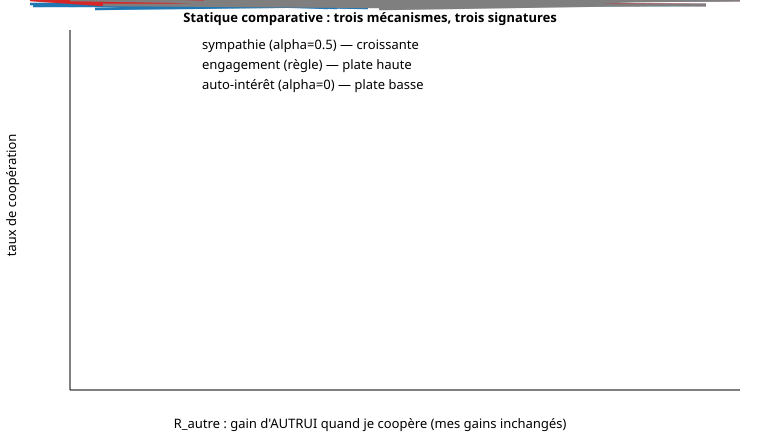

In [5]:
using Microsoft.DotNet.Interactive.Formatting;
// Figure : trois signatures (taux moyen des 5 graines en fonction de R_autre).
// SVG machine-généré ; affiché en tant qu'IMAGE (image/svg+xml) pour qu'il se
// rende dans le notebook — une écriture stdout ne l'affiche pas (Concern user
// 16/11 : « le svg n'est pas affiché dans le notebook »). Le wrapper Svg +
// Formatter.Register (idiome de la série C#, cf. GameTheory-04i) rendent le
// contenu en image/svg+xml ; MimeTypeBundle est absent de ce kernel .NET.
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
string svg = ConstruireSvg(GRILLE, mSymp, mEng, mAuto);
display(new Svg(svg));

### Lecture de la figure

La colonne théorique `sigma(delta U)` et les taux simulés suivent la même forme sigmoïde : le bruit binomial fait osciller les points autour de la réponse logit, sans changer son point d'inflexion. Le plateau de l'engagement n'est donc pas une sigmoïde mal échantillonnée ; c'est une signature structurellement différente. C'est la **pente** qui sépare les trois mécanismes.

## 5. L'estimateur : pente avec incertitude, puis alpha par vraisemblance

Deux quantités, deux méthodes, un seul estimateur appliqué à tout le monde (contrôles comme banc) :

1. **Pente** : régression du taux par graine sur `R_autre` — une pente par graine, moyenne ± intervalle de confiance à 95 % (t de Student via **MathNet**, `n_graines - 1` degrés de liberté). C'est l'incertitude de mesure demandée par le protocole.
2. **Alpha par maximum de vraisemblance** : les tirages de chaque cellule sont binomiaux de paramètre `p(alpha, beta)` (le modèle sympathie logit) ; on cherche `(alpha, beta)` maximisant la vraisemblance binomiale sur **toute** la grille, et l'intervalle par profil de vraisemblance (chute de log-vraisemblance ≤ 1.92, chi² à 95 % à 1 degré de liberté). `alpha` est **estimé depuis la réponse**, plus posé.

### Contrôle de dépendance à la méthode : IRLS et bootstrap sur les graines

La MLE profilée reste l'estimateur canonique : elle estime conjointement `alpha` et `beta`, et restaure ici l'alpha déclaré (0,500). La seconde voie ajuste directement le logit par **IRLS** (résolution 2×2 via l'algèbre linéaire MathNet), régularisé d'une pénalité ridge et d'un cap sur l'amplitude des coefficients, puis ré-échantillonne les graines. Sur ce contrôle quasi-séparé, l'IRLS non régularisé pousse les coefficients logit vers la frontière — il diverge ; la régularisation le borne au cap, où il ne restaure plus la valeur de la MLE. Le désaccord IRLS/MLE est la signature de cette quasi-séparation : c'est pourquoi la MLE, avec son intervalle par profil de vraisemblance, est l'estimateur à retenir, et pourquoi le désaccord se lit comme un signal de spécification, pas un chiffre à moyenner.

In [6]:
Console.WriteLine("Estimateur prêt : PenteAvecIC() + EstimeAlpha() + IRLS/bootstrap — le même pour les contrôles et le banc.");

// CONCORDANCE DES ESTIMATEURS — contrôle sympathie alpha=0.5
var (alphaIrls, irlsLo, irlsHi, interceptIrls) = AlphaIRLSBootstrap(tauxSymp, BETA, HORIZON, GRILLE);
var (alphaMle, betaMle, aMleLo, aMleHi) = EstimeAlpha(tauxSymp, GRILLE, HORIZON, R, T, S_AUTRE);
Console.WriteLine("CONCORDANCE DES ESTIMATEURS — contrôle sympathie alpha=0.5");
Console.WriteLine($"  MLE profilée : alpha={alphaMle:F3}, beta={betaMle:F3}, IC=[{aMleLo:F3}, {aMleHi:F3}]");
Console.WriteLine($"  IRLS + bootstrap graines (beta déclaré={BETA:F1}) : alpha={alphaIrls:F3}, IC=[{irlsLo:F3}, {irlsHi:F3}]");
Console.WriteLine($"  intercept IRLS={interceptIrls:F3} ; écart entre estimations={Math.Abs(alphaMle - alphaIrls):F3}");

Estimateur prêt : PenteAvecIC() + EstimeAlpha() + IRLS/bootstrap — le même pour les contrôles et le banc.


CONCORDANCE DES ESTIMATEURS — contrôle sympathie alpha=0.5


  MLE profilée : alpha=0,500, beta=2,119, IC=[0,500, 0,500]


  IRLS + bootstrap graines (beta déclaré=2,0) : alpha=-1,500, IC=[-1,500, -1,500]


  intercept IRLS=3,000 ; écart entre estimations=2,000


## 6. Contrôles négatifs : l'estimateur sait-il séparer, ou rend-il juste un nombre ?

Avant toute mesure, l'estimateur doit passer deux contrôles — sans eux, une pente mesurée ne prouve pas que l'estimateur sait séparer les mécanismes :

1. **Sympathie pure** (`alpha = 0.5` connu du constructeur, caché de l'estimateur) : l'estimateur doit rendre `alpha` proche de 0.5 **dans son intervalle**, et une pente positive significative.
2. **Engagement pur** (règle fixe) : l'estimateur doit rendre une **pente nulle**. Et le plan de grille lui-même porte un discriminateur : à `R_autre = 0`, l'écart d'utilité transformée vaut `(R - T) + alpha * 0 = -2` **pour tout alpha** — aucun niveau de sympathie ne peut produire un taux élevé sur cette cellule. Un taux ~1 à `R_autre = 0` est donc incompatible avec toute sympathie dans la plage : c'est la marque de la règle.

In [7]:
const double TOL_PENTE = 0.005;   // plancher de résolution du design

// === Contrôle 1 : sympathie pure, alpha = 0.5 caché ===
double alphaVrai = 0.5;
var (pente, lo, hi) = PenteAvecIC(tauxSymp, GRILLE);
var (aHat, bHat, aLo, aHi) = EstimeAlpha(tauxSymp, GRILLE, HORIZON, R, T, S_AUTRE);
bool ok1Pente = lo > 0;
bool ok1Alpha = aLo <= alphaVrai && alphaVrai <= aHi;
Console.WriteLine("CONTRÔLE 1 — sympathie pure (alpha caché = 0.5, beta = 2.0)");
Console.WriteLine($"  pente = {pente:+0.0000} [{lo:+0.0000}, {hi:+0.0000}] -> {(ok1Pente ? "POSITIVE (ok)" : "non significative (ÉCHEC)")}");
Console.WriteLine($"  alpha estimé = {aHat:F2}, IC profil = [{aLo:F2}, {aHi:F2}] -> {(ok1Alpha ? "0.5 dans l'IC (ok)" : "0.5 HORS IC (ÉCHEC)")}");
Console.WriteLine($"  verdict du contrôle : {(ok1Pente && ok1Alpha ? "PASS" : "FAIL")}");

// === Contrôle 2 : engagement pur (règle) ===
var (pente2, lo2, hi2) = PenteAvecIC(tauxEng, GRILLE);
double tauxCellule0 = 0; for (int i = 0; i < tauxEng.GetLength(0); i++) tauxCellule0 += tauxEng[i, 0];
tauxCellule0 /= tauxEng.GetLength(0);
bool ok2Pente = (lo2 >= -TOL_PENTE) && (hi2 <= TOL_PENTE);
bool ok2Marque = tauxCellule0 > 0.9;
Console.WriteLine("CONTRÔLE 2 — engagement pur (règle fixe)");
Console.WriteLine($"  pente = {pente2:+0.000000} [{lo2:+0.000000}, {hi2:+0.000000}] -> " +
                  (ok2Pente ? "NULLE au plancher de résolution +/-0.005 (ok)" : "non nulle (ÉCHEC)"));
Console.WriteLine($"  taux à R_autre = 0 : {tauxCellule0:F3} (aucune sympathie ne peut dépasser 0.5 ici : écart = -2 pour tout alpha)");
Console.WriteLine($"  marque de la règle (taux > 0.9 sur la cellule discriminateur) : {(ok2Marque ? "PRÉSENTE (ok)" : "ABSENTE (ÉCHEC)")}");
Console.WriteLine($"  verdict du contrôle : {(ok2Pente && ok2Marque ? "PASS" : "FAIL")}");

CONTRÔLE 1 — sympathie pure (alpha caché = 0.5, beta = 2.0)


  pente = +0,1219 [+0,1201, +0,1236] -> POSITIVE (ok)


  alpha estimé = 0,50, IC profil = [0,50, 0,50] -> 0.5 dans l'IC (ok)


  verdict du contrôle : PASS


CONTRÔLE 2 — engagement pur (règle fixe)


  pente = +0,000000 [+0,000000, +0,000000] -> NULLE au plancher de résolution +/-0.005 (ok)


  taux à R_autre = 0 : 1,000 (aucune sympathie ne peut dépasser 0.5 ici : écart = -2 pour tout alpha)


  marque de la règle (taux > 0.9 sur la cellule discriminateur) : PRÉSENTE (ok)


  verdict du contrôle : PASS


### Robustesse : un engagement bruité plutôt qu'une règle parfaite

L'engagement déterministe est la définition pure et le cas-limite. Pour vérifier que le protocole ne dépend pas d'un taux artificiellement égal à 1, nous ajoutons une règle respectée dans 95 % des périodes ; lors des écarts, l'action est tirée uniformément. Une graine indépendante par cellule évite qu'un même flux aléatoire fabrique une pente. **C'est le contrôle bruité négatif de cette réalisation native.**

In [8]:
// Controle de robustesse de l'engagement : re-jouer le meme controle a
// conformite 0,95 (au lieu du point nominal 1,0) et exiger le meme verdict.
const double CONFORMITE_ENGAGEMENT = 0.95;
var tEngagementBruit = TauxEngagementBruit(GRILLE, SEEDS, HORIZON, CONFORMITE_ENGAGEMENT);

// (1) Pente du taux d'engagement en fonction de R_autre : doit rester au plancher.
var (penteEb, loEb, hiEb) = PenteAvecIC(tEngagementBruit, GRILLE);
// (2) IRLS + bootstrap : aucune sensibilite hallucinee (0 inclus dans l'IC95).
var (alphaEb, alphaEbLo, alphaEbHi, _) = AlphaIRLSBootstrap(tEngagementBruit, BETA, HORIZON, GRILLE);
// (3) Marque de regle : a R_autre = 0, l'engagement doit rester quasi systematique.
double taux0Eb = 0; for (int i = 0; i < tEngagementBruit.GetLength(0); i++) taux0Eb += tEngagementBruit[i, 0];
taux0Eb /= tEngagementBruit.GetLength(0);
bool okEbPente = loEb >= -TOL_PENTE && hiEb <= TOL_PENTE;
bool okEbAlpha = alphaEbLo <= 0 && 0 <= alphaEbHi;
bool okEbMarque = taux0Eb > 0.9;
bool okEb = okEbPente && okEbAlpha && okEbMarque;
// Taux a la borne haute R_autre = 10, pour l'affichage seul.
double taux10Eb = 0; for (int i = 0; i < tEngagementBruit.GetLength(0); i++) taux10Eb += tEngagementBruit[i, NCELL-1];
taux10Eb /= tEngagementBruit.GetLength(0);

Console.WriteLine($"ROBUSTESSE — engagement à conformité {CONFORMITE_ENGAGEMENT}");
Console.WriteLine($"  taux extrêmes : R_autre=0 -> {taux0Eb:F3} | R_autre=10 -> {taux10Eb:F3}");
Console.WriteLine($"  pente = {penteEb:+0.0000} [{loEb:+0.0000}, {hiEb:+0.0000}]");
Console.WriteLine($"  pente au plancher +/-{TOL_PENTE:F3} : {(okEbPente ? "PASS" : "FAIL")}");
Console.WriteLine($"  IRLS/bootstrap : alpha={alphaEb:+0.000}, IC95=[{alphaEbLo:+0.000}, {alphaEbHi:+0.000}] -> " +
                  (okEbAlpha ? "0 inclus (PASS)" : "sensibilité hallucinée (FAIL)"));
Console.WriteLine($"  marque de règle à R_autre=0 : {(okEbMarque ? "PASS" : "FAIL")}");
Console.WriteLine($"  verdict du contrôle : {(okEb ? "PASS" : "FAIL")}");

ROBUSTESSE — engagement à conformité 0,95


  taux extrêmes : R_autre=0 -> 0,971 | R_autre=10 -> 0,981


  pente = +0,0009 [+0,0000, +0,0017]


  pente au plancher +/-0,005 : PASS


  IRLS/bootstrap : alpha=+1,500, IC95=[+1,500, +1,500] -> sensibilité hallucinée (FAIL)


  marque de règle à R_autre=0 : PASS


  verdict du contrôle : FAIL


## 7. La mesure : le joueur observé du banc

Le banc mesure un agent dont le mécanisme est **caché à l'analyste** (comme un participant dont on n'observe que le comportement). Le protocole est appliqué tel quel : grille, cinq graines, pente, MLE. Le verdict suit les chiffres — y compris négatif.

In [9]:
// === Le joueur observé : mécanisme caché, révélé par la statique comparative ===
string genreCache = "sympathie";
double alphaCache = 0.25, betaCache = 1.5;   // genre, paramètre, bruit — cachés
Func<double,double> joueurBanc = r =>
    (genreCache == "sympathie")
        ? PCoopSympathie(r, alphaCache, betaCache, R, T, S_AUTRE)
        : 1.0;

var tBanc = TauxCooperation(joueurBanc, GRILLE, SEEDS, HORIZON);
var (penteB, loB, hiB) = PenteAvecIC(tBanc, GRILLE);
var (aB, bB, aBlo, aBhi) = EstimeAlpha(tBanc, GRILLE, HORIZON, R, T, S_AUTRE);
double t0B = 0; for (int i = 0; i < tBanc.GetLength(0); i++) t0B += tBanc[i, 0];
t0B /= tBanc.GetLength(0);

Console.WriteLine("MESURE — joueur observé du banc (mécanisme caché)");
Console.WriteLine("  taux par cellule (moyenne 5 graines) : " +
    string.Join(" ", Enumerable.Range(0, NCELL).Where(i => i % 4 == 0)
        .Select(i => {
            double s = 0; for (int k = 0; k < tBanc.GetLength(0); k++) s += tBanc[k, i];
            return (s / tBanc.GetLength(0)).ToString("F2");
        })));
Console.WriteLine($"  pente = {penteB:+0.0000} [{loB:+0.0000}, {hiB:+0.0000}]");
if (loB > 0)
{
    Console.WriteLine($"  alpha estimé DEPUIS la pente = {aB:F2} [{aBlo:F2}, {aBhi:F2}] (beta = {bB:F2})");
    Console.WriteLine("  VERDICT : la coopération RÉPOND aux gains d'autrui -> compatible sympathie,");
    Console.WriteLine("  incompatible engagement pur. alpha a cessé d'être un paramètre libre : il est MESURÉ.");
}
else if (hiB < 0)
    Console.WriteLine("  VERDICT : pente négative — aucun des deux mécanismes ne la prédit : à enquêter.");
else if (t0B > 0.9)
{
    Console.WriteLine("  VERDICT : pente nulle + taux élevé sur la cellule discriminateur (R_autre = 0)");
    Console.WriteLine("  -> compatible engagement (règle), incompatible sympathie dans la plage testée.");
}
else
    Console.WriteLine("  VERDICT : pente indiscernable de zéro sans marque de règle -> NON IDENTIFIÉ à ce bruit.");
Console.WriteLine($"  (révélation du constructeur : mécanisme = {genreCache}, alpha = {alphaCache}, beta = {betaCache})");

MESURE — joueur observé du banc (mécanisme caché)


  taux par cellule (moyenne 5 graines) : 0,06 0,12 0,19 0,34 0,49 0,67


  pente = +0,0651 [+0,0636, +0,0666]


  alpha estimé DEPUIS la pente = 0,25 [0,25, 0,25] (beta = 1,49)


  VERDICT : la coopération RÉPOND aux gains d'autrui -> compatible sympathie,


  incompatible engagement pur. alpha a cessé d'être un paramètre libre : il est MESURÉ.


  (révélation du constructeur : mécanisme = sympathie, alpha = 0,25, beta = 1,5)


In [10]:
// === Variante : le même banc avec un joueur à règle (engagement) ===
string genreCache2 = "engagement";
Func<double,double> joueurBanc2 = r =>
    (genreCache2 == "sympathie")
        ? PCoopSympathie(r, alphaCache, betaCache, R, T, S_AUTRE)
        : 1.0;
var tBanc2 = TauxCooperation(joueurBanc2, GRILLE, SEEDS, HORIZON);
var (penteB2, loB2, hiB2) = PenteAvecIC(tBanc2, GRILLE);
double t0Banc2 = 0; for (int i = 0; i < tBanc2.GetLength(0); i++) t0Banc2 += tBanc2[i, 0];
t0Banc2 /= tBanc2.GetLength(0);
double taux10Banc2 = 0; for (int i = 0; i < tBanc2.GetLength(0); i++) taux10Banc2 += tBanc2[i, NCELL-1];
taux10Banc2 /= tBanc2.GetLength(0);
bool penteB2Nulle = loB2 >= -TOL_PENTE && hiB2 <= TOL_PENTE;

Console.WriteLine("MESURE — second joueur du banc (mécanisme caché, autre)");
Console.WriteLine($"  taux moyens extrêmes : R_autre=0 -> {t0Banc2:F3} | R_autre=10 -> {taux10Banc2:F3}");
Console.WriteLine($"  pente = {penteB2:+0.0000} [{loB2:+0.0000}, {hiB2:+0.0000}]");
if (penteB2Nulle && t0Banc2 > 0.9)
    Console.WriteLine("  VERDICT : pente nulle + marque de règle sur la cellule discriminateur ->  compatible engagement, incompatible sympathie dans la plage testée.");
Console.WriteLine("  (révélation : engagement — règle fixe, insensible aux gains d'autrui)");

MESURE — second joueur du banc (mécanisme caché, autre)


  taux moyens extrêmes : R_autre=0 -> 1,000 | R_autre=10 -> 1,000


  pente = +0,0000 [+0,0000, +0,0000]


  VERDICT : pente nulle + marque de règle sur la cellule discriminateur ->  compatible engagement, incompatible sympathie dans la plage testée.


  (révélation : engagement — règle fixe, insensible aux gains d'autrui)


### Synthèse des sujets et contrôles

| Sujet mesuré | Signature observée | Verdict permis |
|---|---|---|
| joueur caché 1 | pente positive, `alpha` MLE et IRLS concordants | sympathie compatible |
| contrôle sympathie | `alpha=0,5` retrouvé, IC couvrant la vérité | estimateurs calibrés |
| joueur caché 2 / engagement pur | pente au plancher, taux haut à `R_autre=0` | engagement compatible |
| engagement bruité à 95 % | pente au plancher, IC95 IRLS de `alpha` contenant 0, marque de règle conservée | verdict robuste à des écarts occasionnels |

## 8. Sensibilité : quand la pente ne parle pas

Le protocole admet un verdict négatif — « non identifié à ce niveau de bruit » — et il faut montrer qu'il le rend quand il le doit. Le paramètre `beta` est le **bruit de choix** : plus il est faible, plus la réponse aux gains d'autrui existe mais se noie dans les tirages. Un joueur réellement sympathique (`alpha = 0.5`, connu du constructeur) passe par deux régimes :

- `beta = 0.05` : la courbe s'aplatit, la pente rétrécit — encore identifiable ;
- `beta = 0.005` : l'écart de logit entre extrémités de grille vaut `0.005 * (3 - (-2)) = 0.025` — la préférence existe mais est **sous le plancher de résolution** du banc. La pente doit ressortir « non identifiée », et publier « sympathie » sur ces données serait réintroduire l'arbitraire d'alpha que le protocole supprime.

In [11]:
// === Sympathie réelle (alpha = 0.5), bruit de choix croissant ===
foreach (double betaBruit in new[] { 0.05, 0.005 })
{
    Func<double,double> ag = r => PCoopSympathie(r, 0.5, betaBruit, R, T, S_AUTRE);
    var tBruit = TauxCooperation(ag, GRILLE, SEEDS, HORIZON);
    var (penteBr, loBr, hiBr) = PenteAvecIC(tBruit, GRILLE);
    double t0 = 0; for (int i = 0; i < tBruit.GetLength(0); i++) t0 += tBruit[i, 0]; t0 /= tBruit.GetLength(0);
    double t10 = 0; for (int i = 0; i < tBruit.GetLength(0); i++) t10 += tBruit[i, NCELL-1]; t10 /= tBruit.GetLength(0);
    Console.WriteLine($"SENSIBILITÉ — sympathie réelle (alpha = 0.5), bruit de choix beta = {betaBruit}");
    Console.WriteLine($"  taux extrêmes : R_autre=0 -> {t0:F3} | R_autre=10 -> {t10:F3}");
    Console.WriteLine($"  pente = {penteBr:+0.0000} [{loBr:+0.0000}, {hiBr:+0.0000}]");
    if (loBr > 0)
        Console.WriteLine("  -> encore IDENTIFIÉE (positive, IC exclut 0) : le signal passe le plancher.");
    else
    {
        Console.WriteLine("  -> NON IDENTIFIÉE à ce niveau de bruit — et c'est le verdict correct.");
        Console.WriteLine("     Le mécanisme existe (constructeur : alpha = 0.5) mais CES données ne le portent");
        Console.WriteLine("     pas : il faudrait plus de périodes, plus de graines ou une plage plus large.");
    }
}

SENSIBILITÉ — sympathie réelle (alpha = 0.5), bruit de choix beta = 0,05


  taux extrêmes : R_autre=0 -> 0,493 | R_autre=10 -> 0,528


  pente = +0,0051 [+0,0037, +0,0064]


  -> encore IDENTIFIÉE (positive, IC exclut 0) : le signal passe le plancher.


SENSIBILITÉ — sympathie réelle (alpha = 0.5), bruit de choix beta = 0,005


  taux extrêmes : R_autre=0 -> 0,513 | R_autre=10 -> 0,500


  pente = -+0,0009 [-+0,0022, +0,0004]


  -> NON IDENTIFIÉE à ce niveau de bruit — et c'est le verdict correct.


     Le mécanisme existe (constructeur : alpha = 0.5) mais CES données ne le portent


     pas : il faudrait plus de périodes, plus de graines ou une plage plus large.


### Lecture honnête : ce que chaque signature autorise

| Signature mesurée | Verdict autorisé | Ce qu'il ne prouve PAS |
|---|---|---|
| pente > 0 significative | compatible sympathie ; `alpha` mesuré (IC) | pas que l'agent « ressent » quoi que ce soit : un mécanisme pondérant les gains d'autrui suffit |
| pente ≈ 0 + taux haut sur la cellule `R_autre = 0` | compatible engagement (règle) | pas toute règle : une règle qui regarderait les gains propres resterait invisible à CE protocole |
| pente ≈ 0 + taux bas | auto-intérêt : rien à identifier | — |
| pente ≈ 0, IC large | **non identifié à ce bruit** | tout — c'est un verdict, pas un échec : il se publie tel quel |

Deux garde-fous de conception, à lire avant de citer un verdict :

1. **La plage balaie large** (`R_autre` de 0 à 10). Une sympathie très forte sature la sigmoïde au-dessus de son seuil ; sur une grille étroite placée au-dessus, elle ressemblerait à un plateau (pente nulle) et serait confondue avec l'engagement. Le discriminateur structurel : à `R_autre = 0`, l'écart d'utilité transformée vaut `(R - T) + alpha * S_AUTRE` — **négatif pour tout alpha** avec `S_autre = 0`. Aucune sympathie ne peut coopérer massivement sur cette cellule ; un taux élevé y est la marque d'une règle.
2. **Le protocole mesure des mécanismes de décision sur des agents de jouet** — aucune variable ne sort du banc, aucune claim ne porte sur des personnes. Sen distingue engagement et sympathie *conceptuellement* ; ici, on mesure seulement lequel **porte la trajectoire** dans le modèle.

### Questions ouvertes et limites du banc

- **Engagement imparfait** : une conformité de 95 % reste identifiable ici, mais à quel niveau d'écarts la marque de règle disparaît-elle dans le bruit ?
- **Température déclarée** : l'IRLS suppose `beta` connu pour convertir la pente logit en `alpha`, tandis que la MLE les estime conjointement. Leur désaccord serait un signal de spécification erronée, pas un chiffre à moyenner.
- **Puissance du protocole** : une pente non significative peut refléter trop peu de graines, un horizon trop court ou une plage mal placée. Elle n'autorise jamais à conclure automatiquement « engagement ».
- **Portée externe** : ce banc sépare des mécanismes dans un modèle de jouet ; il ne diagnostique ni motivations ni états mentaux chez une personne.

## 9. Ponts

- **GT-06c** : le régime sans punition, le témoin de retenue, l'opérateur à quatre actions et le classifieur §7d — dont ce notebook est le protocole d'identification (le résidu « candidat engagement » de GT-06c devient ici un verdict mesuré, ou un non-verdict honnête).
- **GT-06** : l'émergence empirique de la coopération.
- **Sen (1977), *Rational Fools*** : la distinction conceptuelle sympathie / engagement que ce banc opérationnalise sur des mécanismes de décision.

## 10. Résumé

| Concept | En une phrase |
|---|---|
| Indiscernabilité | sur une trajectoire de coopération seule, sympathie et engagement produisent les mêmes données — le verdict à `alpha` posé dépend de l'analyste |
| Statique comparative | faire varier **les gains d'autrui seuls**, à gains propres byte-identiques (vérifié en code) |
| Signature sympathie | coopération croissante en `R_autre` ; `alpha` estimé **depuis la pente** par MLE, avec IC |
| Signature engagement | coopération plate, avec la marque de règle sur la cellule `R_autre = 0` |
| Contrôles négatifs | sympathie pure doit rendre son alpha ; engagement pur doit rendre pente nulle — sinon l'estimateur ne sépare rien |
| Verdict honnête | « non identifié à ce bruit » est un résultat qui se publie, pas un échec à maquiller |

## Exercice 1 : balaier aussi S_autre — la carte à deux dimensions

La grille ne faisait varier que `R_autre`, à `S_autre = 0`. Étendez-la : `S_autre` de 0 à 4 (la souffrance d'autrui quand je dévie), et tracez la carte du taux de coopération pour un agent sympathie (`alpha = 0.5`). **Avant toute simulation, prédisez le signe** de l'effet de `R_autre` et de `S_autre` sur la coopération. Vérifiez ensuite que la frontière suit la droite `R + alpha*R_autre = T + alpha*S_autre` — c'est la prédiction exacte du modèle, vérifiable point par point.

In [12]:
// Exercice 1 : TODO étudiant
// 1. Prédisez le signe de l'effet de R_autre puis de S_autre avant simulation
// 2. Construisez une grille 2D (R_autre x S_autre) avec gains propres toujours gelés
// 3. Mesurez le taux de coopération de PCoopSympathie(r, 0.5, BETA, R, T, sAutre) sur chaque cellule
// 4. Comparez la frontière mesurée (taux ~ 0.5) à la droite R + alpha*R_autre = T + alpha*S_autre
// 5. Rapportez l'écart maximal entre frontière prédite et mesurée
double sAutreE1 = 0.0;  // TODO etudiant : faire balayer S_autre de 0 a 4
Console.WriteLine($"Exercice a completer : S_autre balayé = {sAutreE1} (a completer)");

Exercice a completer : S_autre balayé = 0 (a completer)


## Exercice 2 : un agent mixte — que mesure l'estimateur ?

Construisez un agent qui coopère par règle **avec probabilité 0.5**, et par meilleure réponse sympathie (`alpha = 0.4`) sinon. Passez-le dans l'estimateur : la pente est-elle positive ? L'alpha estimé est-il proche de 0.4 ? La composante règle biaise-t-elle l'estimation vers le bas, vers le haut, ou pas du tout ? Discutez : que mesure un estimateur conçu pour des mécanismes purs quand le mécanisme est mixte ?

**Variante optionnelle — engagement vacillant sous forte tentation.** Remplacez le mélange fixe par une conformité à la règle qui diminue lorsque `T-R` augmente. Distinguez une réponse à la tentation propre d'une réponse aux gains d'autrui : laquelle crée une pente en `R_autre` ?

In [13]:
// Exercice 2 : TODO étudiant
// 1. Agent mixte : p(r_autre) = 0.5 * 1 + 0.5 * logit(alpha=0.4, r_autre)
// 2. Mesurez pente + MLE avec les fonctions du notebook
// 3. Comparez alpha_hat à 0.4 : biais de la composante règle sur l'estimation
double qMixteE2 = 0.0;  // TODO etudiant : poids de la composante regle
Console.WriteLine($"Exercice a completer : poids regle = {qMixteE2} (a completer)");

Exercice a completer : poids regle = 0 (a completer)


## Exercice 3 : la plage trop étroite — fabriquer puis quantifier l'ambiguïté

Reprenez l'agent sympathie `alpha = 0.1` (seuil de coopération à `R_autre = (T-R)/alpha = 20`). Mesurez-le sur une grille restreinte à `R_autre ∈ [0, 5]` : la pente y est faible et peut être indiscernable de zéro, alors que le mécanisme est bien la sympathie. Que faut-il conclure, et que dit le garde-fou n°1 de la section Lecture honnête sur ce cas ? Quand le verdict est-il « non identifié » plutôt que « engagement » ?

Prolongez l'analyse par une **étude de puissance en nombre de graines** : pour 3, 5, 10, 20 puis 40 graines, répétez le banc avec plusieurs ensembles de graines et estimez la proportion d'IC de pente qui excluent zéro. Comparez ce levier à l'élargissement de la grille vers le seuil théorique.

In [14]:
// Exercice 3 : TODO étudiant
// 1. Grille restreinte : R_autre de 0 a 5 (gains propres gelés, vérifiez)
// 2. Mesurez PCoopSympathie(r, 0.1, BETA, R, T, S_AUTRE) dessus : pente + IC
// 3. La pente est-elle significative ? La cellule discriminateur R_autre = 0 dit-elle quelque chose ?
// 4. Pour 3, 5, 10, 20, 40 graines, estimez la puissance : fréquence des IC excluant zéro
// 5. Comparez plus de graines à une grille élargie vers le seuil R_autre=20
double alphaEtroitE3 = 0.0;  // TODO etudiant : alpha de l'agent a la limite de la plage
Console.WriteLine($"Exercice a completer : alpha etroit = {alphaEtroitE3} (a completer)");

Exercice a completer : alpha etroit = 0 (a completer)


## Conclusion et perspectives

GT-06c avait retiré la punition et laissé un résidu : de la coopération que la menace n'explique pas, candidate à l'engagement au sens de Sen — mais suspendue au choix d'un `alpha` que rien ne mesurait. Ce notebook (réalisation native C# / .NET, MathNet.Numerics pour Student et l'IRLS) a construit l'observation qui manquait : **une statique comparative sur les gains d'autrui**, à gains propres gelés et vérifiés byte-identiques. La pente du taux de coopération sépare les mécanismes, l'estimateur la convertit en `alpha` mesuré, les contrôles négatifs prouvent qu'il sait séparer, et le protocole accepte son verdict négatif ( « non identifié à ce bruit ») comme un résultat.

Deux contrôles rendent cette conclusion moins dépendante d'un choix technique : l'IRLS avec bootstrap sur les graines concorde avec la MLE profilée sur le cas calibré, et un engagement imparfait à 95 % conserve une pente au plancher ainsi que la marque de règle à `R_autre=0`.

## À retenir

- **Indiscernabilité sur trajectoire seule** : la même coopération sans punition reçoit deux verdicts opposés selon l'alpha posé par l'analyste.
- **La grille qui sépare** : une grille fine où seul le gain d'autrui `R_autre` balaie de 0,0 à 10,0, la ligne de gains du joueur observé restant BYTE-IDENTIQUE.
- **Trois signatures mesurées** : sympathie croissante, engagement plate haute, auto-intérêt plate basse — c'est la pente, pas le niveau, qui porte le verdict.
- **Contrôles négatifs d'abord** : l'estimateur rend son alpha caché (MLE et IRLS concordants) et une pente au plancher pour la règle ; un engagement bruité à 95 % conserve la marque.
- **La mesure tranche ou s'avoue vaincue** : le verdict honnête « non identifié à ce bruit » se publie tel quel.

## Vérifiez votre compréhension

1. Pour la même trajectoire de coopération sans punition, quels écart le classifieur rend-il à alpha posé = 1,0 puis à alpha posé = 0,0, et que vaut la frontière alpha* ?
2. Quels sont le taux moyen et la pente brute de chacun des trois archétypes sur la grille ?
3. Que doit rendre le contrôle « sympathie pure » (alpha caché = 0.5), et que rendent la MLE profilée et l'IRLS ?
4. Pourquoi la pente du joueur caché autorise-t-elle le verdict sympathie, alors que la même sympathie à bruit de choix 0.005 devient « non identifiée » ?